In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
# import custom 3CA dataloader
pth_3ca, name = os.path.split(os.getcwd())
sys.path.append(pth_3ca)
from scripts.load import load_CCCA_adata

In [3]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{name}')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)

In [4]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
msk = (adata.obs.celltype == 'Malignant')
adata = adata[msk].copy(); adata

Loading ../../../../data/unzip/CCCA/Data_Puram2017_Head-and-Neck
Done.


AnnData object with n_obs × n_vars = 2539 × 23686
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype'
    uns: 'log1p'

In [5]:
# inspect per-sample cell counts
n = adata.obs['sample'].value_counts(); n

sample
20    676
17    353
26    284
18    263
25    229
6     157
28    149
5     138
22    123
16    100
12     23
13     15
24     13
7       6
10      6
8       3
9       1
Name: count, dtype: int64

In [6]:
# threshold using inflection point
keep = n.index[n >= 100]  # min cells
msk = adata.obs['sample'].isin(keep)
adata = adata[msk].copy(); adata

AnnData object with n_obs × n_vars = 2472 × 23686
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype'
    uns: 'log1p'

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4804 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.



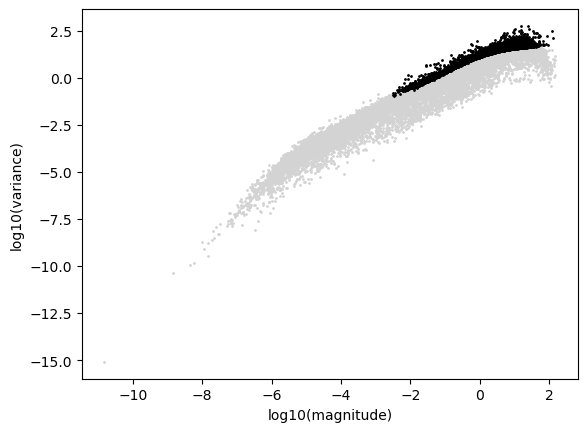

In [7]:
# filter + select highly variable genes
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata, plot = True)

In [8]:
# pca -> integrate samples
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'sample')

2026-07-14 22:31:13,574 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-14 22:31:14,259 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-14 22:31:14,279 - harmonypy - INFO - Iteration 1 of 10
2026-07-14 22:31:14,792 - harmonypy - INFO - Iteration 2 of 10
2026-07-14 22:31:15,278 - harmonypy - INFO - Iteration 3 of 10
2026-07-14 22:31:15,754 - harmonypy - INFO - Iteration 4 of 10
2026-07-14 22:31:16,233 - harmonypy - INFO - Iteration 5 of 10
2026-07-14 22:31:16,716 - harmonypy - INFO - Iteration 6 of 10
2026-07-14 22:31:17,199 - harmonypy - INFO - Converged after 6 iterations


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


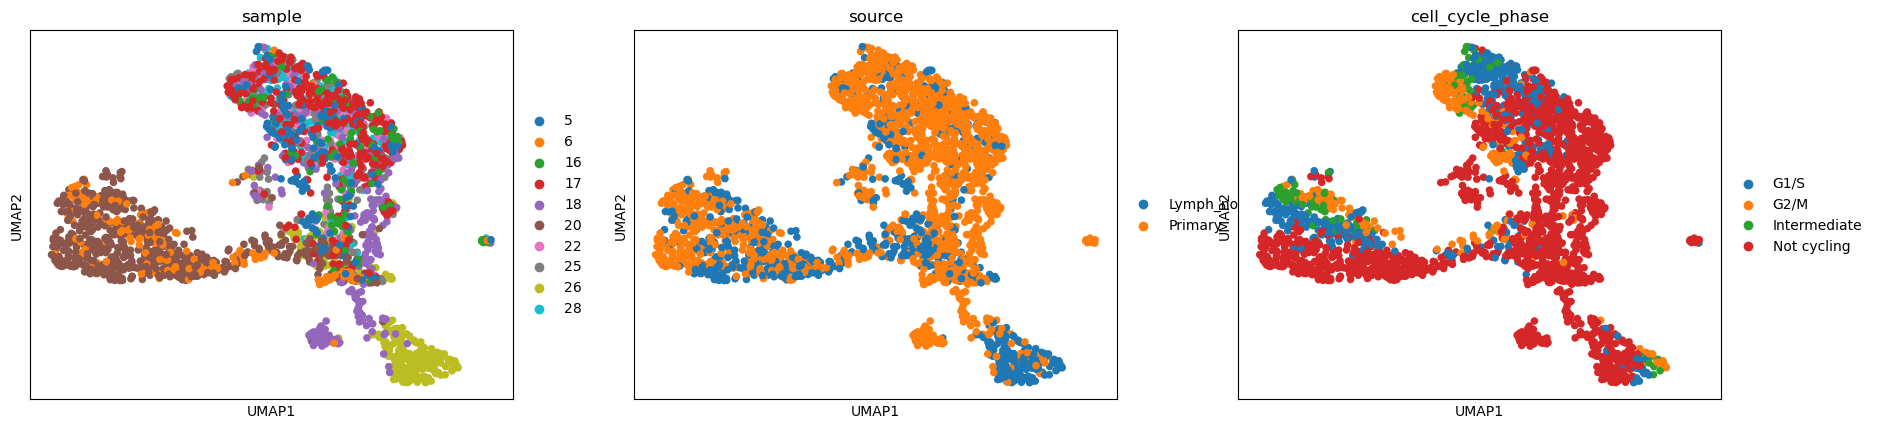

In [9]:
# nearest neighbors -> umap embedding -> visual inspection
# tune n_pcs, spread to optimize tree/trajectory structure(s)
c = ['sample', 'source', 'cell_cycle_phase']
sc.pp.neighbors(adata, n_pcs = 40, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, spread = 1.3)
sc.pl.umap(adata, color = c, size = 120)

/tmp/ipykernel_1863456/2127096653.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution = 1.5)


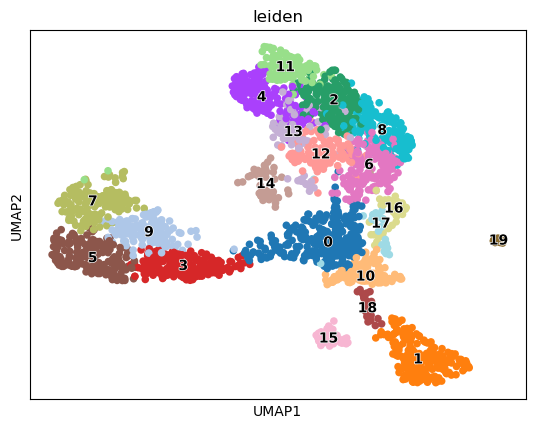

In [10]:
# cluster cells -> visual inspection
# tune resolution to isolate detached clusters
sc.tl.leiden(adata, resolution = 1.5)
sc.pl.umap(adata, color = 'leiden', size = 120,
           legend_loc = 'on data',
           legend_fontoutline = True)

In [11]:
# remove detached clusters from adata
remove = np.array([14, 15, 19], dtype = str)
adata = adata[~adata.obs.leiden.isin(remove)].copy()
adata

AnnData object with n_obs × n_vars = 2356 × 20435
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'source_colors', 'cell_cycle_phase_colors', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

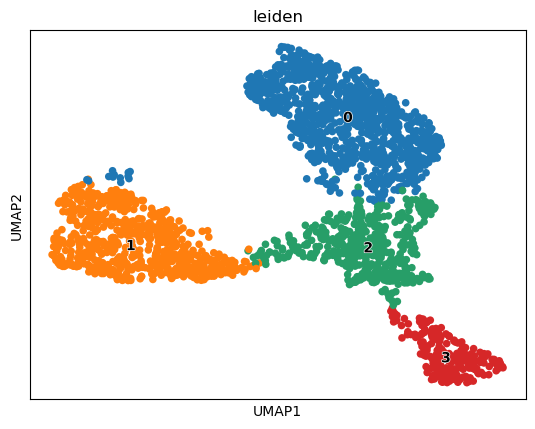

In [12]:
# re-cluster cells -> visual inspection
# tune resolution to segregate segments
sc.tl.leiden(adata, resolution = .2)
sc.pl.umap(adata, color = 'leiden', size = 120,
           legend_loc = 'on data',
           legend_fontoutline = True)

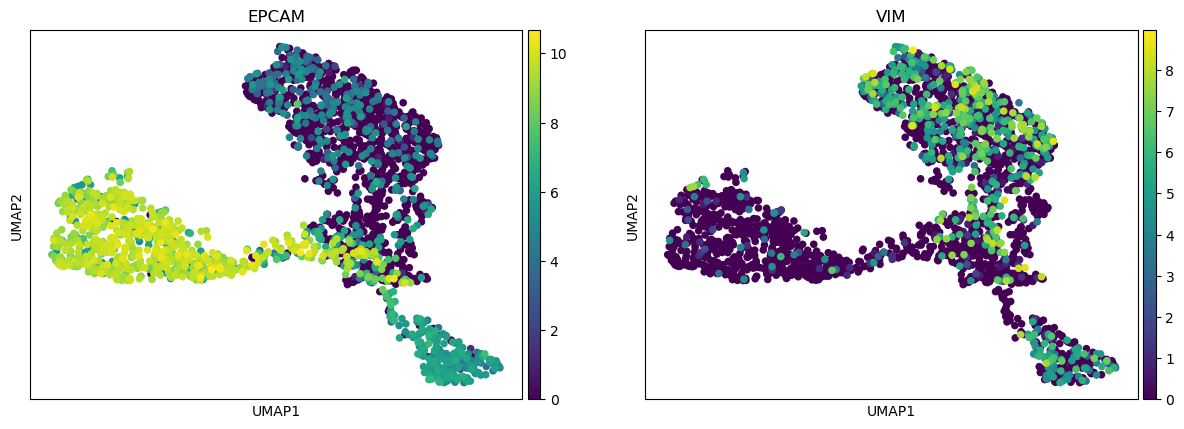

In [13]:
# visual inspection — E/M markers
c = ['EPCAM',   # Epithelial
     'VIM']     # Mesenchymal
sc.pl.umap(adata, color = c, size = 120)

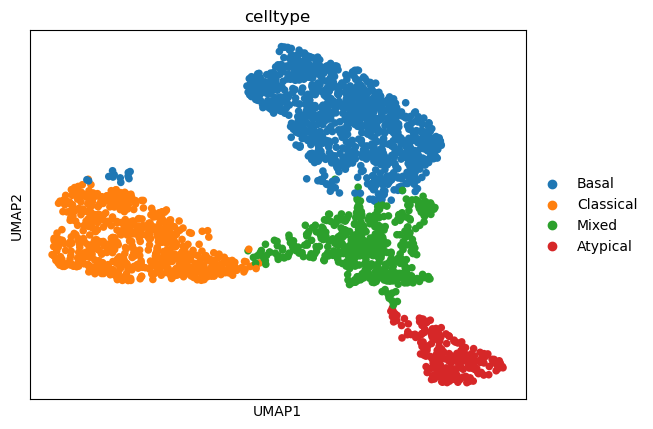

In [14]:
celltype_dict = {
    '0' : 'Basal',
    '1' : 'Classical',
    '2' : 'Mixed',
    '3' : 'Atypical'}

# annotate cell types from original publication
adata.obs['celltype'] = (adata.obs.leiden
                         .map(celltype_dict)
                         .astype('category'))
sc.pl.umap(adata, color = 'celltype', size = 120)

In [15]:
# save processed data to h5ad file
adata.write(os.path.join(pth_out, 'processed.h5ad'))

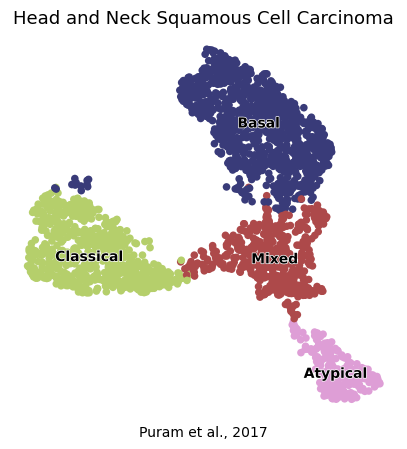

In [16]:
# save cell type embedding for publication
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'celltype', size = 120,
           palette = 'tab20b', legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
title = 'Head and Neck Squamous Cell Carcinoma'
label = 'Puram et al., 2017'
ax.set_title(title, size = 13)
ax.text(.5, -.05, label, ha = 'center',
        transform = ax.transAxes)
fn = os.path.join(pth_fig, 'processed.pdf')
plt.savefig(fn, bbox_inches = 'tight')